# Stage 2 — reproducible pilot dataset
Selection uses the first 730 days only, with seed 42 and balanced coverage across store/category and demand/volume groups. See `docs/pilot_selection.md` for exact rules and limitations. Rebuild with `python -m src.data.pipeline` from the project root.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data.pipeline import select_pilot
config = json.loads((ROOT / "configs/pilot.json").read_text())
profiles = pd.read_csv(ROOT / "data/processed/series_profiles.csv")
manifest = pd.read_csv(ROOT / "data/processed/pilot_series.csv")
pilot = pd.read_csv(ROOT / "data/processed/pilot_daily.csv.gz", parse_dates=["date"])
display(config)

{'seed': 42,
 'n_series': 200,
 'profile_days': 730,
 'intermittent_zero_fraction': 0.5,
 'volatile_cv': 1.0}

## Confirm reproducible membership
Profiles contain only sampling-window statistics. Inactive series are excluded; the cohort represents established products and cannot establish new-product cold-start performance.

In [2]:
reselected = select_pilot(profiles, config)
assert reselected.id.tolist() == manifest.id.tolist()
print("Reproducible selection:", len(manifest), "series")
display(pd.crosstab(manifest.store_id, manifest.cat_id))
display(pd.crosstab(manifest.demand_type, manifest.volume_band))
display(manifest.groupby("state_id").size().rename("series"))

Reproducible selection: 200 series


cat_id,FOODS,HOBBIES,HOUSEHOLD
store_id,,,
CA_1,7,6,6
CA_2,7,6,7
CA_3,7,7,6
CA_4,6,6,7
TX_1,7,7,7
TX_2,6,7,6
TX_3,7,7,7
WI_1,7,7,7
WI_2,7,7,6


volume_band,high,low,medium
demand_type,,,
intermittent,36,39,39
stable,33,0,7
volatile,34,1,11


state_id
CA    78
TX    61
WI    61
Name: series, dtype: int64

## Long-format data
Every row is one item/store/day. Calendar fields are joined by `d`; price fields by item/store/week. No price imputation is applied.

In [3]:
print("Pilot shape:", pilot.shape)
print("Dates:", pilot.date.min(), "to", pilot.date.max())
display(pilot.head())
assert not pilot.duplicated(["series_id", "date"]).any()
assert pilot.groupby("series_id").size().eq(1941).all()
assert pilot.units_sold.notna().all() and pilot.units_sold.ge(0).all()
print("Missing price rows:", pilot.price_missing.sum())
print("Positive sales with missing price:", (pilot.price_missing & pilot.units_sold.gt(0)).sum())

Pilot shape: (388200, 23)
Dates: 2011-01-29 00:00:00 to 2016-05-22 00:00:00


,series_id,item_id,dept_id,cat_id,store_id,state_id,d,units_sold,date,wm_yr_wk,...,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price,price_missing
0,FOODS_1_029_WI_1_evaluation,FOODS_1_029,FOODS_1,FOODS,WI_1,WI,d_1,0,2011-01-29,11101,...,2011,NaN,NaN,NaN,NaN,0,0,0,NaN,True
1,FOODS_1_029_WI_1_evaluation,FOODS_1_029,FOODS_1,FOODS,WI_1,WI,d_2,0,2011-01-30,11101,...,2011,NaN,NaN,NaN,NaN,0,0,0,NaN,True
2,FOODS_1_029_WI_1_evaluation,FOODS_1_029,FOODS_1,FOODS,WI_1,WI,d_3,0,2011-01-31,11101,...,2011,NaN,NaN,NaN,NaN,0,0,0,NaN,True
3,FOODS_1_029_WI_1_evaluation,FOODS_1_029,FOODS_1,FOODS,WI_1,WI,d_4,0,2011-02-01,11101,...,2011,NaN,NaN,NaN,NaN,1,1,0,NaN,True
4,FOODS_1_029_WI_1_evaluation,FOODS_1_029,FOODS_1,FOODS,WI_1,WI,d_5,0,2011-02-02,11101,...,2011,NaN,NaN,NaN,NaN,1,0,1,NaN,True


Missing price rows: 18508
Positive sales with missing price: 0


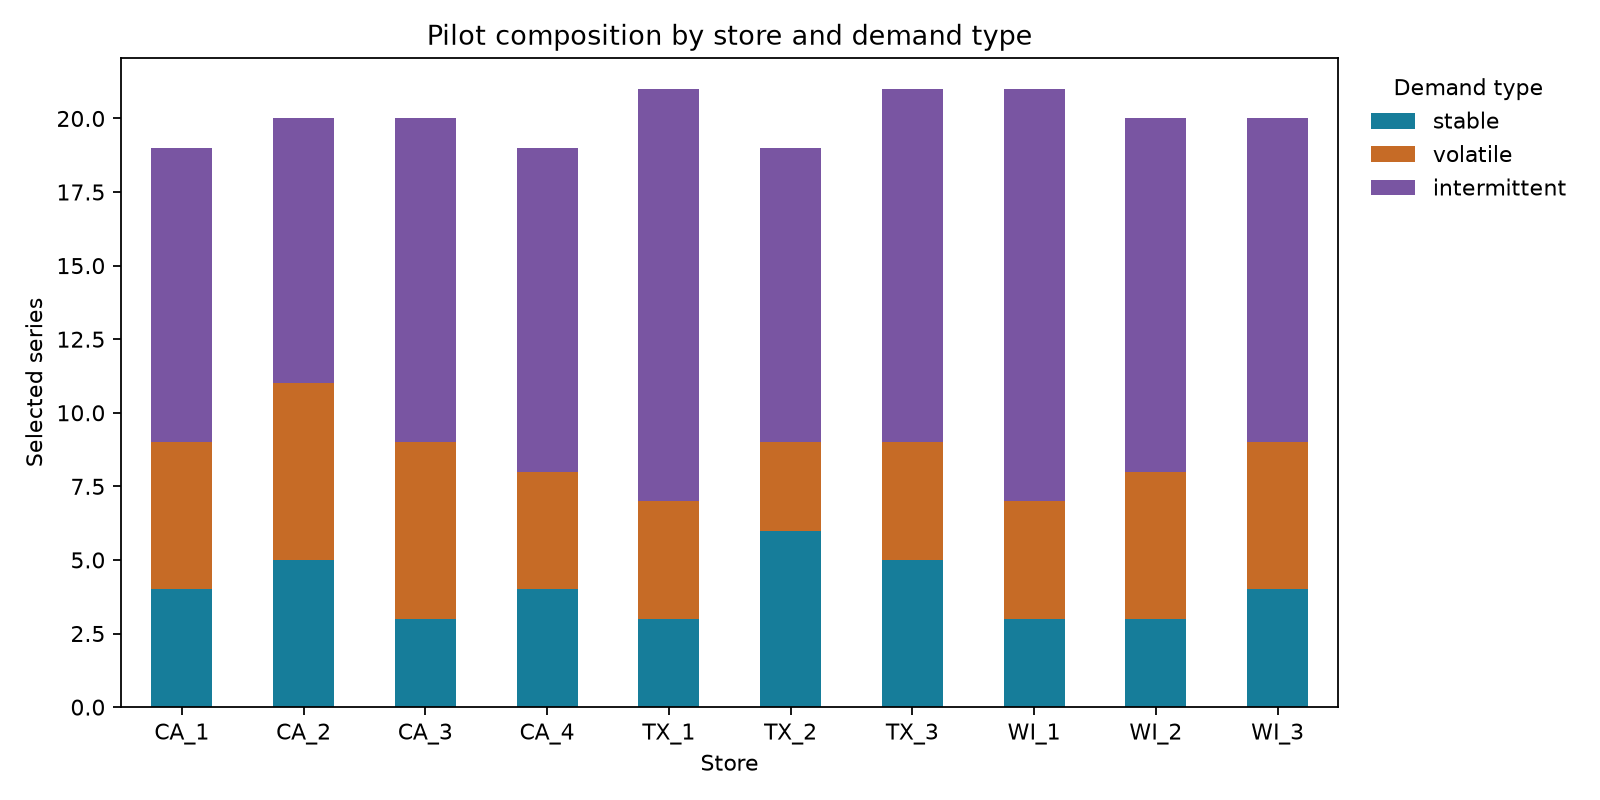

In [4]:
display(Image(filename=str(ROOT / "results/figures/pilot_composition.png")))

## Stop before modeling
The pilot is ready. The reviewed core evaluation rules are locked in `docs/evaluation_protocol.md` (v1.0). Model-specific execution details must be finalized using validation only before test runs; no models have been implemented. Raw and processed files are ignored by Git; the manifest, audit, and plots provide a reviewable record.